# Grape Sugar Content (°Brix) Prediction from NIR and Raman Spectroscopy

This notebook reproduces the Vis-NIR + Raman case study from the Spectra-Scope
manuscript (Ebrahimi et al. 2024 dataset).  It predicts total soluble solids
(°Brix, sugar content) in wine grapes and generates all main-text and
supplementary figures for that case study.

**Figures produced**
| File | Description |
|------|-------------|
| `Figures/SuppFig2.pdf` | SI Fig 2 – Random Forest cross-validation results |
| `Figures/Fig4.pdf` | Main text Fig 4 – performance heatmap + feature selection |
| `Figures/SuppFig5.pdf` | SI Fig 5 – RF feature importance |
| `Figures/SuppFig6.pdf` | SI Fig 6 – LCEN feature importance |
| `Figures/Fig6.pdf` | Main text Fig 6 – correlation assessment |
| `Figures/Fig5.pdf` | Main text Fig 5 – Fused LASSO coefficients |

In [1]:
import sys
%load_ext autoreload
%autoreload 2

import copy
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image

from sklearn.base import clone
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.feature_selection import r_regression
from sklearn.preprocessing import StandardScaler

from spectrascope.SpectraScope import *
from spectrascope.Features import SpectralFeatures
from spectrascope.FusedLasso import FusedLasso
from spectrascope.SSPlotting import PlotModel as pm, PlotSpectralFeatures as psf
from spectrascope.utils import predict_LCEN, LCEN_selected_features

plt.style.use('../ss.mplstyle')

# Human-readable labels for feature/modality combinations
PRETTY_LABELS_DICT = {
    'nir_pointwise_features':        'NIR, Intensity',
    'rm_pointwise_features':         'Raman, Intensity',
    'nir_polynomial_featuresall':    'NIR, Polynomial',
    'rm_polynomial_featuresall':     'Raman, Polynomial',
    'nir_cdf':                       'NIR, CDF',
    'rm_cdf':                        'Raman, CDF',
    'nir_pca':                       'NIR, PCA',
    'rm_pca':                        'Raman, PCA',
    'nir_featureagg':                'NIR, Clustering',
    'rm_featureagg':                 'Raman, Clustering',
    'rm_nir_pointwise_features':     'NIR + Raman, Intensity',
    'nir_rm_polynomial_featuresall': 'NIR + Raman, Polynomial',
    'nir_cwt':                       'NIR, CWT',
}

/Users/amalyajohnson/miniconda3/envs/fin/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/amalyajohnson/miniconda3/envs/fin/lib/python3.11/site-packages/matminer/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
def add_all_features(ss):
    """Add all spectral feature types to a SpectraScope object."""
    for spec in ss.specnames:
        xaxis = getattr(ss, f'{spec}_xaxis')
        ss.add_spectral_feature(spec, 'pointwise_features', xrange=xaxis)
        ss.add_spectral_feature(spec, 'polynomial_featuresall')
        ss.add_spectral_feature(spec, 'featureagg', n_clusters=15)
        ss.add_spectral_feature(spec, 'pca', n_components=15)
        ss.add_spectral_feature(spec, 'cdf')
    ss.add_spectral_feature('nir', 'fft_features', xrange=ss.nir_xaxis)
    ss.combine_feature('rm_pointwise_features', 'nir_pointwise_features')


def train_all_models(ss, feats, feats_lcen,
                     RF_kwargs, Linear_kwargs, Lasso_kwargs,
                     fused_kwargs, lcen_kwargs, ss_unscaled=None):
    """Train RF, Linear, Lasso, Fused Lasso, and LCEN on all feature sets.

    Parameters
    ----------
    ss_unscaled : SpectraScope or None
        Unscaled copy (same random seed) used for Fused Lasso fits.
        Fused Lasso uses its own global max-std standardization, so
        per-feature StandardScaler must be bypassed. If None, falls
        back to ss (previous behavior).
    """
    # Scikit-learn models
    for spec in ss.specnames:
        for feat in feats:
            attr = f'{spec}_{feat}'
            ss.do_sk(attr, 'br', 0.25, use_pipeline=True,  **RF_kwargs)
            ss.do_sk(attr, 'br', 0.25, use_pipeline=False, **Linear_kwargs)
            ss.do_sk(attr, 'br', 0.25, use_pipeline=True,  **Lasso_kwargs)
    ss.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True,  **RF_kwargs)
    ss.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=False, **Linear_kwargs)
    ss.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=True,  **Lasso_kwargs)
    # Fused Lasso — use unscaled object to avoid per-feature StandardScaler
    _fused_ss = ss_unscaled if ss_unscaled is not None else ss
    _fused_sk = {k: v for k, v in fused_kwargs.items()
                 if k not in ('param_grid', 'refit', 'scoring')}
    for spec in _fused_ss.specnames:
        for feat in feats:
            try:
                _fused_ss.do_sk(f'{spec}_{feat}', 'br', 0.25, use_pipeline=False,
                                scale_X=False, **_fused_sk)
            except RuntimeError:
                continue
    # LCEN
    for spec in ss.specnames:
        for feat in feats_lcen:
            ss.do_LCEN(f'{spec}_{feat}', 'br', 0.25, **lcen_kwargs)
    ss.do_LCEN('rm_nir_pointwise_features', 'br', 0.25, **lcen_kwargs)


def run_lcen_sensitivity(ss, attr, resp, frac, param_arr, param_name,
                          fixed_alpha, fixed_cutoff, fixed_l1):
    """Sweep one LCEN hyperparameter while holding the others fixed.

    Parameters
    ----------
    param_name : 'alpha', 'cutoff', or 'l1_ratio'
    param_arr  : sequence of values to sweep
    fixed_*    : values held constant during the sweep
    """
    results = []
    for val in param_arr:
        kwargs = dict(
            l1_ratio=[val if param_name == 'l1_ratio' else fixed_l1],
            cv_method=None,
            degree=[1],
            alpha=[val if param_name == 'alpha' else fixed_alpha],
            LCEN_cutoff=(val if param_name == 'cutoff' else fixed_cutoff),
            lag=[0],
            trans_type='poly',
            LCEN_interaction=False,
            scale_X=True,
            scale_y=True,
            metric=root_mean_squared_error,
        )
        ss.do_LCEN(attr, resp, frac, **kwargs)
        prmse = getattr(ss, f'{attr}_{resp}_LCEN')['score'] / np.max(ss.br) * 100
        results.append(prmse)
    return results


def plot_spectral_features_matplotlib(xaxis, raw, selected_features, ax=None,
                                       zoom=0.1, plot_raw=True, print_centers=False):
    """Overlay polynomial-fit icons on a raw spectrum for selected feature regions."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    if plot_raw:
        ax.plot(xaxis, raw, color='black', lw=1)

    temp = SpectralFeatures(xaxis, raw)
    for bins in [4, 5, 10, 20]:
        temp.generate_bins(bins)

    feature_config = [
        (0,   16,  'bin_indices_4',  'const', 4),
        (16,  36,  'bin_indices_5',  'line',  5),
        (36,  76,  'bin_indices_10', 'par',   10),
        (76,  156, 'bin_indices_20', 'cubic', 20),
    ]

    def find_nearest(array, value):
        return np.abs(array - value).argmin()

    centers_used = []
    for selected_id in selected_features:
        for id_min, id_max, bin_label, poly_label, num_bins in feature_config:
            if id_min <= selected_id < id_max:
                search_bins = np.linspace(id_min, id_max, num_bins)
                located_bin = np.argwhere(selected_id < search_bins)[0][0]
                bin_mask = getattr(temp, bin_label) == located_bin
                center = np.median(xaxis[bin_mask])
                height = raw[find_nearest(xaxis, center)]
                img_path = f'../app/static/{poly_label}.png'
                if not os.path.exists(img_path):
                    continue
                im = Image.open(img_path)
                imagebox = OffsetImage(im, zoom=zoom)
                add_to_height = 1 if center in centers_used else 0
                ab = AnnotationBbox(imagebox, (center, height + add_to_height), frameon=False)
                centers_used.append(center)
                if print_centers:
                    pass
                ax.add_artist(ab)
                break
    return ax


def plot_two_heatmaps(df, sort_by, vrange1, vrange2, ax,
                       cm1='viridis', cm2='flare', annot_kws=None):
    """Overlay two seaborn heatmaps (correlation metric and RMSE) on one axes."""
    (vmin1, vmax1), (vmin2, vmax2) = vrange1, vrange2
    cmap1 = plt.get_cmap(cm1).copy()
    cmap1.set_under('none')
    cmap2 = plt.get_cmap(cm2).copy()
    cmap2.set_over('none')
    ax1 = sns.heatmap(df.sort_values(sort_by), vmin=vmin1, vmax=vmax1,
                       annot=True, cmap=cmap1, cbar_kws={'pad': 0.2},
                       ax=ax, annot_kws=annot_kws)
    sns.heatmap(df.sort_values(sort_by), vmin=vmin2, vmax=vmax2,
                cmap=cmap2, ax=ax1, cbar_kws={'pad': 0.2}, annot_kws=annot_kws)
    cbar1 = ax.collections[0].colorbar
    cbar2 = ax.collections[1].colorbar
    return ax, cbar1, cbar2

## Load Data

Raw spectra and target values (°Brix) are stored in the test files directory.
Original dataset: Ebrahimi et al. (2024), Vis-NIR and Raman spectra from two grape varieties.

In [3]:
XSF_br    = np.load('../tests/test_files/grapes_example/XSF_br.npy')
XRF_br    = np.load('../tests/test_files/grapes_example/XRF_br.npy')
br        = np.load('../tests/test_files/grapes_example/br.npy')
nir_wls   = np.load('../tests/test_files/grapes_example/nir_xaxis.npy')
raman_wls = np.load('../tests/test_files/grapes_example/rm_xaxis.npy')

## Visualize Raw Spectra

One representative NIR (Vis-NIR) and Raman spectrum to inspect signal quality.

Text(0.5, 0.98, 'Raw Data')

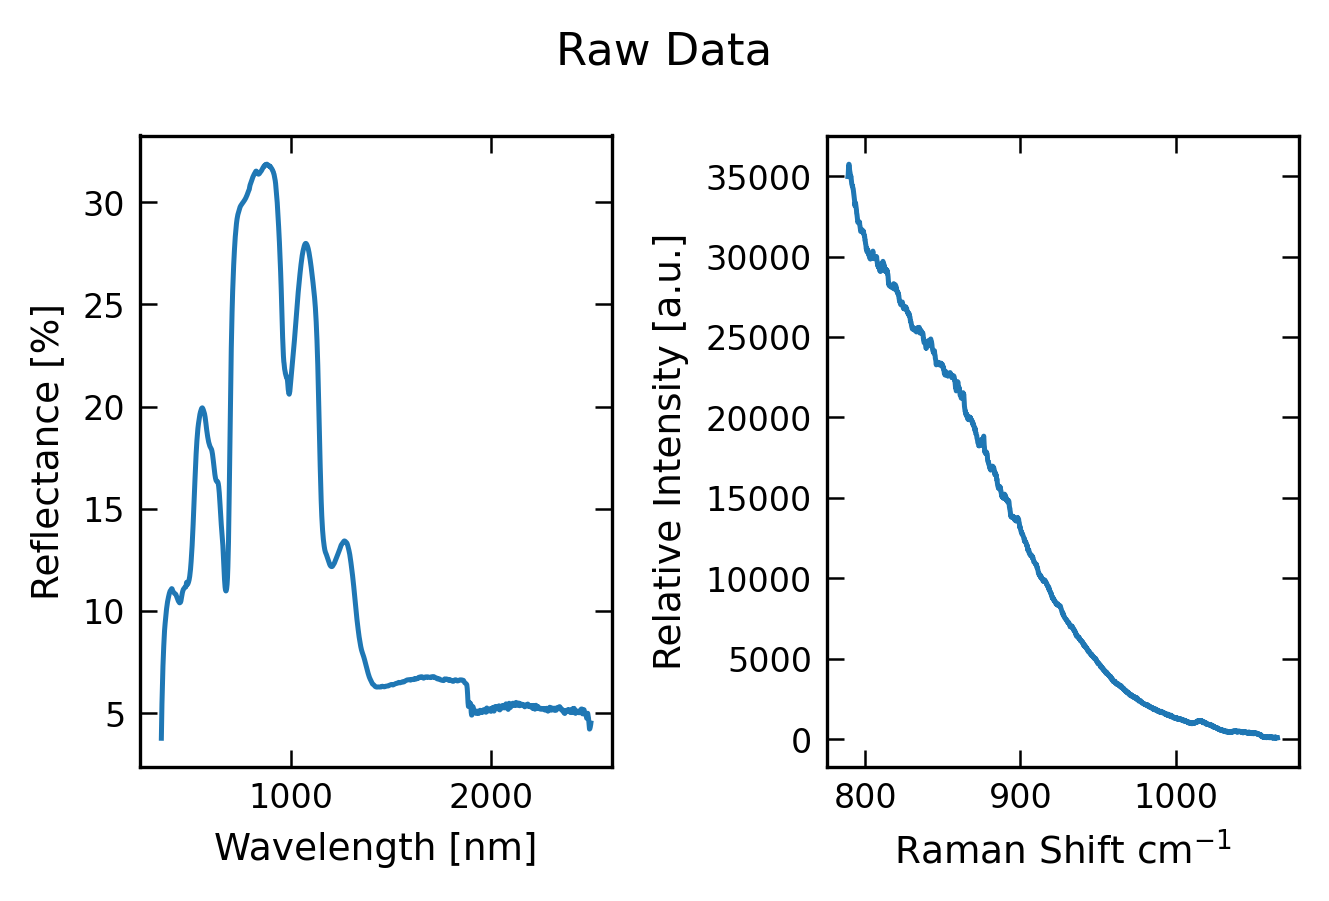

In [4]:
f, (ax1, ax2) = plt.subplots(1, 2)
ax1.plot(nir_wls, XSF_br[0])
ax2.plot(raman_wls, XRF_br[0])
ax1.set_xlabel('Wavelength [nm]')
ax1.set_ylabel('Reflectance [%]')
ax2.set_xlabel(rf'Raman Shift $cm^{{-1}}$')
ax2.set_ylabel('Relative Intensity [a.u.]')
f.suptitle('Raw Data')

## Preprocess: Center and Scale

Each spectrum is mean-centered and standardized (`StandardScaler`),
following Ebrahimi et al. NIR spectra are restricted to 400–1300 nm
where absorption is strongest.

In [5]:
# Mean-center each spectrum
XSF_br_centered = np.zeros(XSF_br.shape)
for i, arr in enumerate(XSF_br):
    XSF_br_centered[i] = arr - np.mean(arr)

XRF_br_centered = np.zeros(XRF_br.shape)
for i, arr in enumerate(XRF_br):
    XRF_br_centered[i] = arr - np.mean(arr)

scaler = StandardScaler()
XSF_br_centered_scaled = scaler.fit_transform(XSF_br_centered)
XRF_br_centered_scaled = scaler.fit_transform(XRF_br_centered)

# Restrict NIR to 400-1300 nm
selected_wls = np.argwhere((nir_wls > 400) & (nir_wls < 1300))[:, 0]
XSF_br_centered_scaled = XSF_br_centered_scaled[:, selected_wls]

XF = [XSF_br_centered_scaled, XRF_br_centered_scaled]

## Initialize SpectraScope

Create a `SpectraScope` object and register all spectral feature types
for both the NIR (`nir`) and Raman (`rm`) modalities.
Features include: pointwise intensities, CDF, polynomial fits, PCA, clustering,
wavelet transforms (CWT), FFT, and the combined NIR + Raman intensity matrix.

In [6]:
ss_f = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=42)
ss_f.add_x_axis('rm', raman_wls)
ss_f.add_x_axis('nir', nir_wls[selected_wls])
add_all_features(ss_f)

# Unscaled copy for Fused Lasso (same seed ensures identical splits)
ss_f_unscaled = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=42)
ss_f_unscaled.add_x_axis('rm', raman_wls)
ss_f_unscaled.add_x_axis('nir', nir_wls[selected_wls])
add_all_features(ss_f_unscaled)

/Users/amalyajohnson/Desktop/Spectrascope-Review/spectrascope/spectrascope/SpectraScope.py:134: UserWarning: No save_path specified; defaulting to 'output/'. Pass save_path to override.
  warnings.warn(
/Users/amalyajohnson/Desktop/Spectrascope-Review/spectrascope/spectrascope/SpectraScope.py:134: UserWarning: No save_path specified; defaulting to 'output/'. Pass save_path to override.
  warnings.warn(


## Set Up Hyperparameter Grids for Cross-Validation

Define `kwargs` dicts for each model type:
- **Random Forest** (RF): grid search over `n_estimators` and `max_depth`
- **LCEN**: sweep `l1_ratio` and `alpha`; polynomial degree-1 nonlinear expansion
- **Lasso / Linear**: standard sklearn estimators
- **Fused Lasso**: contiguous-coefficient LASSO suited to spectral data

See SI Tables 1 and 2 for the full hyperparameter grids.

In [7]:
RF_kwargs = {
    'estimator':  RandomForestRegressor(random_state=42),
    'param_grid': {'n_estimators': [50, 100, 200],
                   'criterion':    ['squared_error'],
                   'max_depth':    [50, None]},
    'refit':      True,
    'scale_X':    False,
    'metric':     root_mean_squared_error,
    'scoring':    'neg_mean_squared_error',
}

lcen_kwargs = {
    'l1_ratio':         [0.001, 0.01, 0.1, 0.3, 0.5, 0.75, 1],
    'K_fold':           5,
    'cv_method':        'Kfold',
    'alpha':            5,
    'degree':           [1],
    'trans_type':       'poly',
    'LCEN_cutoff':      5e-5,
    'LCEN_interaction': False,
    'scale_X':          True,
    'scale_y':          True,
    'metric':           root_mean_squared_error,
}

Lasso_kwargs = {
    'estimator':  Lasso(),
    'param_grid': {'alpha': [0.1, 0.3, 0.5, 0.9], 'fit_intercept': [True]},
    'refit':      True,
    'metric':     root_mean_squared_error,
}

Linear_kwargs = {'estimator': LinearRegression()}

fused_kwargs = {
    'estimator':  FusedLasso(),
    'param_grid': {'alpha': [0.3, 0.5, 0.9], 'fit_intercept': [True]},
    'refit':      True,
    'scoring':    'neg_mean_squared_error',
    'metric':     root_mean_squared_error,
}

feats      = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']
feats_lcen = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']

## Train Scikit-Learn and LCEN Models

Train all model/feature combinations on the main dataset (`ss_f`).
The additional single Fused Lasso fit on raw NIR intensity data is also
included here; it is used in Figure 5.

In [ ]:
train_all_models(ss_f, feats, feats_lcen,
                 RF_kwargs, Linear_kwargs, Lasso_kwargs, fused_kwargs, lcen_kwargs,
                 ss_unscaled=ss_f_unscaled)

# Extra single Fused Lasso fit on NIR intensity (used in Figure 5)
ss_f_unscaled.do_sk('nir_pointwise_features', 'br', 0.25, use_pipeline=False,
                     scale_X=False, estimator=FusedLasso(alpha=0.1),
                     metric=mean_squared_error)

## Random Variable Control Experiment

A Gaussian random variable (uncorrelated with °Brix) is appended to every
feature matrix before retraining all models.  The importance / coefficient
assigned to this random variable provides a per-model significance threshold:
any real feature selected *less* prominently than the random variable
carries no statistically meaningful signal.

In [11]:
ss_rv = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=42)
ss_rv.add_x_axis('rm', raman_wls)
ss_rv.add_x_axis('nir', nir_wls[selected_wls])
add_all_features(ss_rv)

# Unscaled copy for Fused Lasso (same seed ensures identical splits)
ss_rv_unscaled = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=42)
ss_rv_unscaled.add_x_axis('rm', raman_wls)
ss_rv_unscaled.add_x_axis('nir', nir_wls[selected_wls])
add_all_features(ss_rv_unscaled)

np.random.seed(42)
for feat in ss_rv.generated_features:
    feat_arr = getattr(ss_rv, feat)
    random_var = np.random.randn(feat_arr.shape[0], 1)
    setattr(ss_rv, feat, np.append(feat_arr, random_var, axis=1))
    # Same random variable appended to unscaled copy
    setattr(ss_rv_unscaled, feat, np.append(getattr(ss_rv_unscaled, feat), random_var, axis=1))

train_all_models(ss_rv, feats, feats_lcen,
                 RF_kwargs, Linear_kwargs, Lasso_kwargs, fused_kwargs, lcen_kwargs,
                 ss_unscaled=ss_rv_unscaled)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.5962 | Mean relative error = 0.0282
Test set : RMSE = 1.0173 | Mean relative error = 0.0497
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.2684 | Mean relative error = 0.1011
Test set : RMSE = 2.6637 | Mean relative error = 0.1175
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

In [12]:
# Extract importance / coefficient of the appended random variable for each model
rv_importance = {}
for feat in ss_rv.generated_features:
    # RF: importance of the last (random) feature
    try:
        rf = getattr(ss_rv, f'{feat}_br_RandomForestRegressor')['P'][0]
        rv_importance[f'{feat}_br_RandomForestRegressor'] = (
            rf.best_estimator_.feature_importances_[-1]
        )
    except Exception:
        continue
    # LCEN: absolute coefficient of the random feature (0 if not selected)
    try:
        model_params = np.array(getattr(ss_rv, f'{feat}_br_LCEN')['model_params'])
        n_real  = getattr(ss_rv, feat).shape[1] - 1
        rv_name = f'x{n_real}'
        rv_coef = next(
            (abs(float(v)) for n, v in model_params if n == rv_name), 0.0
        )
        rv_importance[f'{feat}_br_LCEN'] = rv_coef
    except Exception:
        continue

## SI Figure 2: Random Forest Cross-Validation Results

Per-fold % RMSE for each hyperparameter combination across all feature/modality pairs.
See SI Table 4 for the tabular summary of best and worst hyperparameter splits.

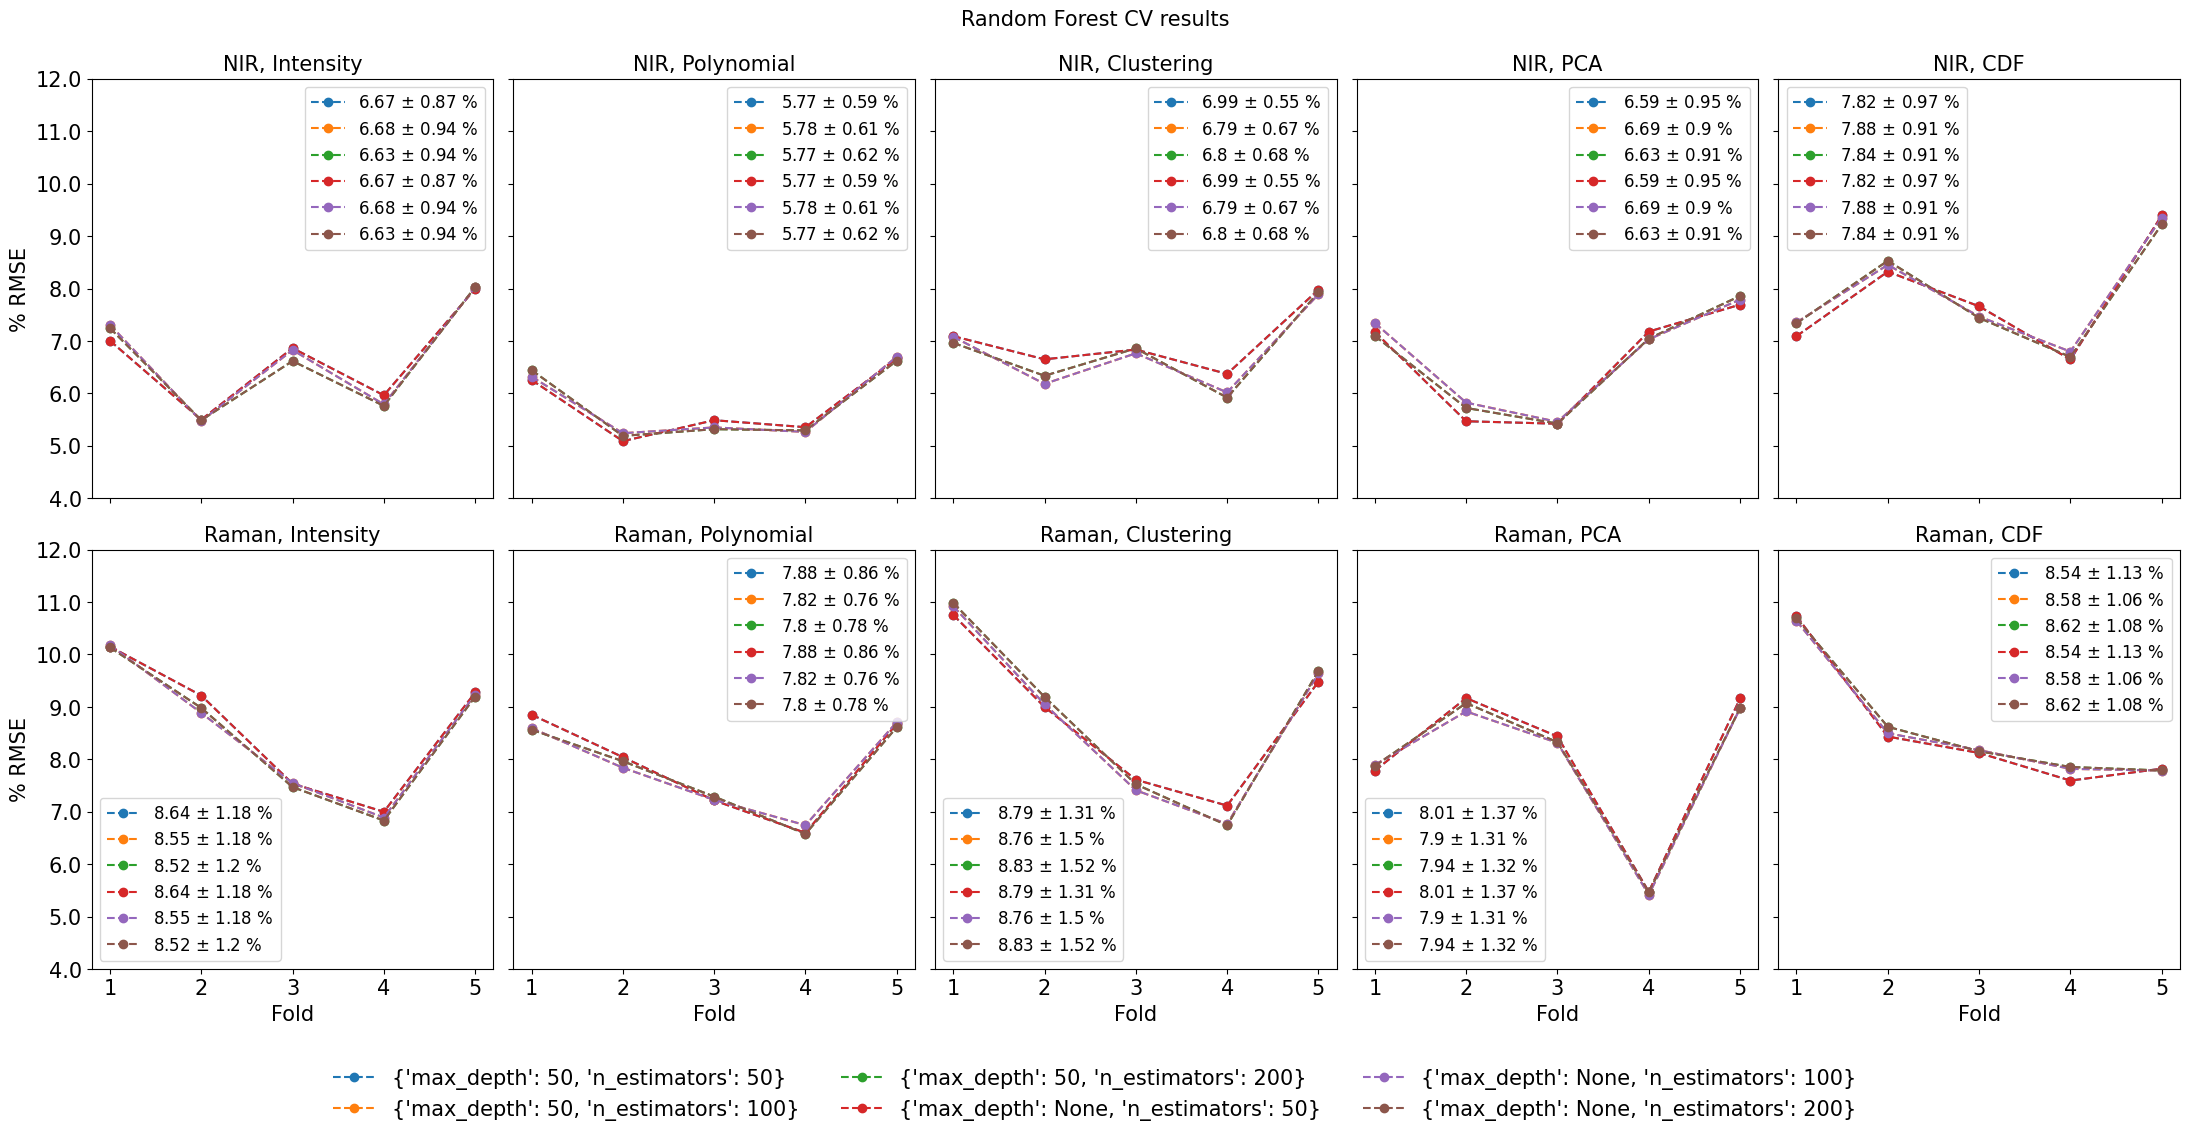

In [28]:
f, axs = plt.subplots(2, 5, figsize=(22, 10), sharex=True, sharey=True)
axs = axs.ravel()
idx = 0
rf_cv_table = []
legend_handles = []

split_cols = ['split0_test_score', 'split1_test_score', 'split2_test_score',
              'split3_test_score', 'split4_test_score']

for attr_name in ss_f.generated_features:
    try:
        gs = getattr(ss_f, f'{attr_name}_br_RandomForestRegressor')['P'][0]
    except AttributeError:
        continue
    if 'rm_nir' in attr_name:
        continue
    cv_results = pd.DataFrame(gs.cv_results_)
    if cv_results.empty:
        continue

    row_handles = []
    for _, row in cv_results.iterrows():
        scores = row[split_cols].astype(float)
        prmse  = np.sqrt(np.abs(scores)) * 100 / np.max(ss_f.br)
        params = {'max_depth': row['params']['max_depth'],
                  'n_estimators': row['params']['n_estimators']}
        row_handles.append(params)
        axs[idx].plot(np.arange(5), prmse,
                      label=f"{np.round(np.mean(prmse),2)} $\\pm$ {np.round(np.std(prmse),2)} %",
                      marker='o', linestyle='--')
        axs[idx].legend(fontsize=12)
        axs[idx].set_title(PRETTY_LABELS_DICT.get(attr_name, attr_name), size=15)
    if idx == 0:
        legend_handles = row_handles

    def _param_str(p):
        return '(' + ', '.join(str(p[k]) for k in ['max_depth', 'n_estimators']) + ')'

    # Find best and worst performing hyperparams for each feature and save results in the same row
    best_idx = cv_results['mean_test_score'].idxmax()
    worst_idx = cv_results['mean_test_score'].idxmin()

    # Best fold
    s_best = cv_results.loc[best_idx, split_cols].astype(float)
    s_best = np.sqrt(np.abs(s_best)) * 100 / np.max(ss_f.br)
    p_best = cv_results.loc[best_idx, 'params']

    # Worst fold
    s_worst = cv_results.loc[worst_idx, split_cols].astype(float)
    s_worst = np.sqrt(np.abs(s_worst)) * 100 / np.max(ss_f.br)
    p_worst = cv_results.loc[worst_idx, 'params']

    rf_cv_table.append({
        'Feature': PRETTY_LABELS_DICT.get(attr_name, attr_name),
        'Best (mean \u00b1 std)': f'{np.mean(s_best):.2f} \u00b1 {np.std(s_best):.2f}',
        'Best hyperparams (depth, N)': _param_str(p_best),
        'Worst (mean \u00b1 std)': f'{np.mean(s_worst):.2f} \u00b1 {np.std(s_worst):.2f}',
        'Worst hyperparams (depth, N)': _param_str(p_worst),
    })
    idx += 1

handles, _ = axs[-1].get_legend_handles_labels()
f.legend(handles, legend_handles, loc='lower center', fontsize=15,
         bbox_to_anchor=(0.5, -0.1), ncols=3, frameon=False)
axs[0].set_ylabel('% RMSE', fontsize=15)
axs[5].set_ylabel('% RMSE', fontsize=15)
for j in range(5, 10):
    axs[j].set_xlabel('Fold', fontsize=15)
for ax in axs:
    ax.set_xticks([0, 1, 2, 3, 4], labels=[1, 2, 3, 4, 5], fontsize=15)
    ax.set_yticks(ax.get_yticks(), labels=np.round(ax.get_yticks(), 2), fontsize=15)
plt.tight_layout()
f.suptitle('Random Forest CV results', fontsize=15, y=1.03)
plt.savefig('Figures/SuppFig2.pdf')

#### RF cross-validation results (Grapes dataset, SI Table 4)

In [29]:
df_cv = pd.DataFrame(rf_cv_table)
print(df_cv.to_latex(index=True,
                     caption='RF cross-validation results (Grapes dataset, SI Table 4)',
                     label='tab:grapes_rf_cv', escape=False))

\begin{table}
\caption{RF cross-validation results (Grapes dataset, SI Table 4)}
\label{tab:grapes_rf_cv}
\begin{tabular}{llllll}
\toprule
 & Feature & Best (mean ± std) & Best hyperparams (depth, N) & Worst (mean ± std) & Worst hyperparams (depth, N) \\
\midrule
0 & NIR, Intensity & 6.63 ± 0.94 & (50, 200) & 6.68 ± 0.94 & (50, 100) \\
1 & NIR, Polynomial & 5.77 ± 0.59 & (50, 50) & 5.78 ± 0.61 & (50, 100) \\
2 & NIR, Clustering & 6.79 ± 0.67 & (50, 100) & 6.99 ± 0.55 & (50, 50) \\
3 & NIR, PCA & 6.59 ± 0.95 & (50, 50) & 6.69 ± 0.90 & (50, 100) \\
4 & NIR, CDF & 7.82 ± 0.97 & (50, 50) & 7.88 ± 0.91 & (50, 100) \\
5 & Raman, Intensity & 8.52 ± 1.20 & (50, 200) & 8.64 ± 1.18 & (50, 50) \\
6 & Raman, Polynomial & 7.80 ± 0.78 & (50, 200) & 7.88 ± 0.86 & (50, 50) \\
7 & Raman, Clustering & 8.76 ± 1.50 & (50, 100) & 8.83 ± 1.52 & (50, 200) \\
8 & Raman, PCA & 7.90 ± 1.31 & (50, 100) & 8.01 ± 1.37 & (50, 50) \\
9 & Raman, CDF & 8.54 ± 1.13 & (50, 50) & 8.62 ± 1.08 & (50, 200) \\
\bottomrule
\e

## LCEN Cross-Validation Results

Evaluate LCEN predictions on held-out folds using the same `KFold` splitter.

In [15]:
kf = KFold(n_splits=5, random_state=12, shuffle=True)

cv_results_lcen = {}
for spec in ss_f.specnames:
    for feat in feats_lcen:
        attr_name = f'{spec}_{feat}'
        X, y = getattr(ss_f, attr_name), ss_f.br
        fold_scores = []
        for _, test_idx in kf.split(X):
            try:
                ypred = predict_LCEN(getattr(ss_f, f'{attr_name}_br_LCEN'), X[test_idx])
                fold_scores.append(root_mean_squared_error(y[test_idx], ypred))
            except Exception:
                print(f'{attr_name} failed')
                continue
        if fold_scores:
            cv_results_lcen[attr_name] = fold_scores

X, y = ss_f.rm_nir_pointwise_features, ss_f.br
cv_results_lcen['rm_nir_pointwise_features'] = [
    root_mean_squared_error(y[test_idx],
                            predict_LCEN(getattr(ss_f, 'rm_nir_pointwise_features_br_LCEN'),
                                         X[test_idx]))
    for _, test_idx in kf.split(X)
]

## Figure 4: Performance Summary and Feature Selection

**(a)** % RMSE heatmap for all feature/model combinations (RF and LCEN).
**(b–c)** Raw NIR spectra with the top-10 selected features highlighted,
comparing pointwise-intensity (i) vs. polynomial-fit (ii) representations
for Random Forest (b) and LCEN (c). Blue vertical lines: selected/important
features; characteristic polynomials: selected/important features.

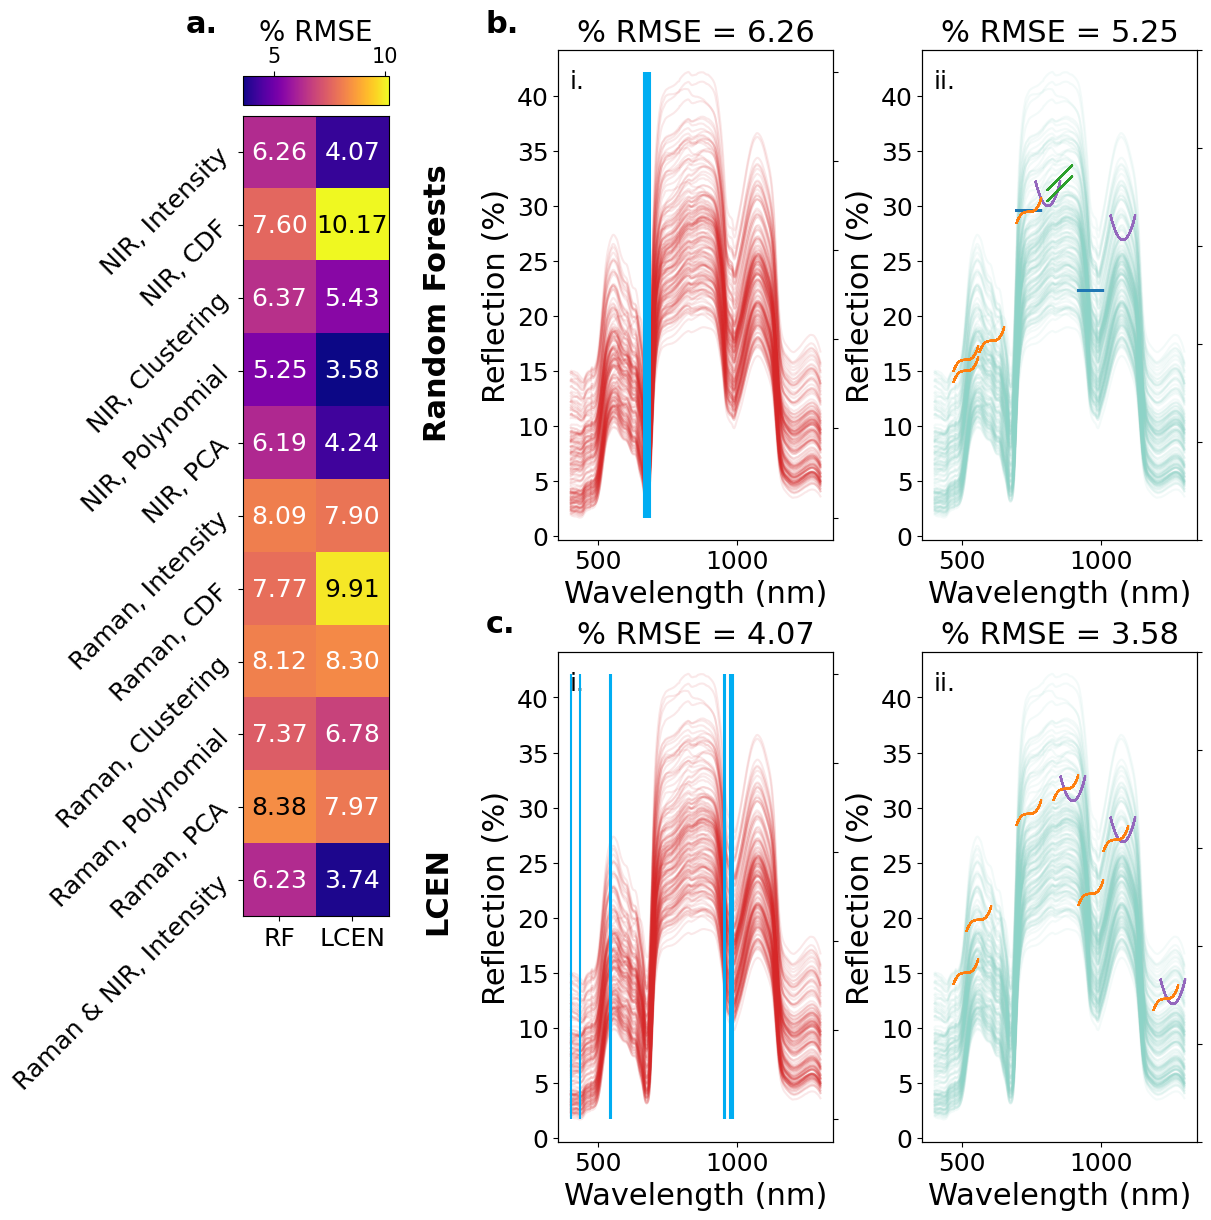

In [16]:
results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)

# Ordered labels for the heatmap y-axis (matches ss_f.generated_features order)
labels = [
    'NIR, Intensity', 'NIR, CDF', 'NIR, Clustering', 'NIR, Polynomial', 'NIR, PCA',
    'Raman, Intensity', 'Raman, CDF', 'Raman, Clustering', 'Raman, Polynomial', 'Raman, PCA',
    'Raman & NIR, Intensity',
]

fontsize      = 22
ticklabelsize = 18

fig = plt.figure(figsize=(12, 12), constrained_layout=True)
outer_gs = gridspec.GridSpec(2, 3, figure=fig,
                              width_ratios=[1, 2.5, 2.5],
                              height_ratios=[1, 1], hspace=0.5, wspace=0.4)
ax1 = fig.add_subplot(outer_gs[:, 0])
inner_top    = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_gs[:, 1], wspace=0.3)
ax4 = fig.add_subplot(inner_top[0])
ax2 = fig.add_subplot(inner_top[1])
inner_bottom = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer_gs[:, 2], wspace=0.3)
ax5 = fig.add_subplot(inner_bottom[0])
ax3 = fig.add_subplot(inner_bottom[1])

ax2_twin = ax2.twinx(); ax3_twin = ax3.twinx()
ax4_twin = ax4.twinx(); ax5_twin = ax5.twinx()

prmse_df = ((results_df.T) / ss_f.br.max()) * 100
prmse_df = prmse_df[['RandomForestRegressor', 'LCEN']]
im = ax1.imshow(prmse_df, cmap='plasma')
ax1.set_yticks(np.arange(len(labels)))
ax1.set_yticklabels(labels, rotation=45, ha='right', size=18)
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['RF', 'LCEN'], size=18)
cb1 = fig.colorbar(im, ax=ax1, location='top', aspect=5, pad=0.01)
cb1.ax.tick_params(labelsize=15)
cb1.set_label('% RMSE', fontsize=20)
thresh_90 = np.percentile(prmse_df.values, 90)
for (i, j), val in np.ndenumerate(prmse_df):
    txt_color = 'black' if val >= thresh_90 else 'white'
    ax1.text(j, i, f'{val:.2f}', ha='center', va='center', color=txt_color, size=ticklabelsize)

spec = 'nir'
for mn, axes in zip(['RandomForestRegressor', 'LCEN'],
                     [(ax4, ax5, ax4_twin), (ax2, ax3, ax2_twin)]):
    ax_i, ax_ii, ax_twin = axes
    rmse = pd.DataFrame(ss_f.best_fits).T[
        ['nir_pointwise_features_br', 'nir_polynomial_featuresall_br']
    ].loc[mn].values
    ax_i.set_title(f'% RMSE = {round(100 * rmse[0] / np.max(ss_f.br), 2)}', fontsize=fontsize)
    ax_ii.set_title(f'% RMSE = {round(100 * rmse[1] / np.max(ss_f.br), 2)}', fontsize=fontsize)
    for spectrum in XSF_br:
        spectrum = spectrum[selected_wls]
        ax_i.plot(ss_f.nir_xaxis, spectrum, color='#d62728', alpha=0.1)
        ax_ii.plot(ss_f.nir_xaxis, spectrum, color=plt.cm.Set3(np.arange(10))[0], alpha=0.1)
    model = getattr(ss_f, f'{spec}_pointwise_features_br_{mn}')
    for k in model['selected_features'][:10]:
        ax_twin.vlines(ss_f.nir_xaxis[k], 0, 1, color='#00ADF2', alpha=1)

plot_spectral_features_matplotlib(
    ss_f.nir_xaxis, XSF_br[0, selected_wls],
    ss_f.nir_polynomial_featuresall_br_RandomForestRegressor['selected_features'][:10],
    ax=ax5, zoom=0.05, plot_raw=False)
plot_spectral_features_matplotlib(
    ss_f.nir_xaxis, XSF_br[0, selected_wls],
    ss_f.nir_polynomial_featuresall_br_LCEN['selected_features'][:10],
    ax=ax3, zoom=0.05, plot_raw=False)

for ax in [ax2, ax3, ax4, ax5]:
    ax.set_xlabel('Wavelength (nm)', fontsize=fontsize)
    ax.set_ylabel('Reflection (%)', fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=ticklabelsize)
    ax.xaxis.label.set_size(fontsize)
    ax.yaxis.label.set_size(fontsize)
for ax in [ax2_twin, ax3_twin, ax4_twin, ax5_twin]:
    ax.set_yticklabels([])

# ── Panel labels (a. b. c.) ──────────────────────────────────────────────────
fig.text(0.15, 0.98, 'a.', 
         fontsize=fontsize, fontweight='bold', va='bottom', ha='left', clip_on=False)
fig.text(0.4, 0.98, 'b.', 
         fontsize=fontsize, fontweight='bold', va='bottom', ha='left', clip_on=False)
fig.text(0.4, 0.48, 'c.', 
         fontsize=fontsize, fontweight='bold', va='bottom', ha='left', clip_on=False)

# ── Subplot labels (i. ii.) ──────────────────────────────────────────────────
for ax, lbl in zip([ax4, ax2, ax5, ax3], ['i.', 'i.', 'ii.', 'ii.']):
    ax.text(0.04, 0.96, lbl, transform=ax.transAxes,
            fontsize=ticklabelsize, va='top', ha='left')

# ── Row labels (Random Forests / LCEN) ───────────────────────────────────────
fig.text(0.36, 0.76, 'Random Forests', 
         fontsize=fontsize, rotation=90, va='center', ha='center', clip_on=False, weight='bold')
fig.text(0.36, 0.27, 'LCEN', 
         fontsize=fontsize, rotation=90, va='center', ha='center', clip_on=False, weight='bold')

# ── Callout annotations ───────────────────────────────────────────────────────
# c.i. (ax2): 'Selected Features' pointing to the blue selected-feature vlines
# ax2.annotate(
#     'Selected\nFeatures',
#     xy=(0.44, 0.16), xycoords='axes fraction',
#     xytext=(0.06, 0.16), textcoords='axes fraction',
#     fontsize=ticklabelsize - 2, va='center',
#     arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
# )

# # b.ii. (ax5): 'Important Features' pointing to a characteristic polynomial
# ax5.annotate(
#     'Important\nFeatures',
#     xy=(0.70, 0.58), xycoords='axes fraction',
#     xytext=(0.28, 0.88), textcoords='axes fraction',
#     fontsize=ticklabelsize - 2, va='top',
#     arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
# )

plt.savefig('Figures/Fig4.pdf', dpi=300, bbox_inches='tight')


### Number of Features Selected by Each LCEN Model

LCEN automatically zeroes out uninformative features; inspect how many
survive the cutoff threshold for the pointwise and polynomial schemes.

In [17]:
print('poly features:',len(ss_f.nir_polynomial_featuresall_br_LCEN['model_params']))
print('num poly features:',len(ss_f.nir_polynomial_featuresall[0]))
print('pointwise features:',len(ss_f.nir_pointwise_features_br_LCEN['model_params']))
print('num pointwise features:',len(ss_f.nir_xaxis))

poly features: 31
num poly features: 157
pointwise features: 88
num pointwise features: 899


## SI Figure 5: Random Forest Feature Importance

Horizontal bar plots for every feature/modality pair.
Red dashed line = importance of the random (uncorrelated) variable
from the control experiment; features above this threshold carry
statistically meaningful signal.

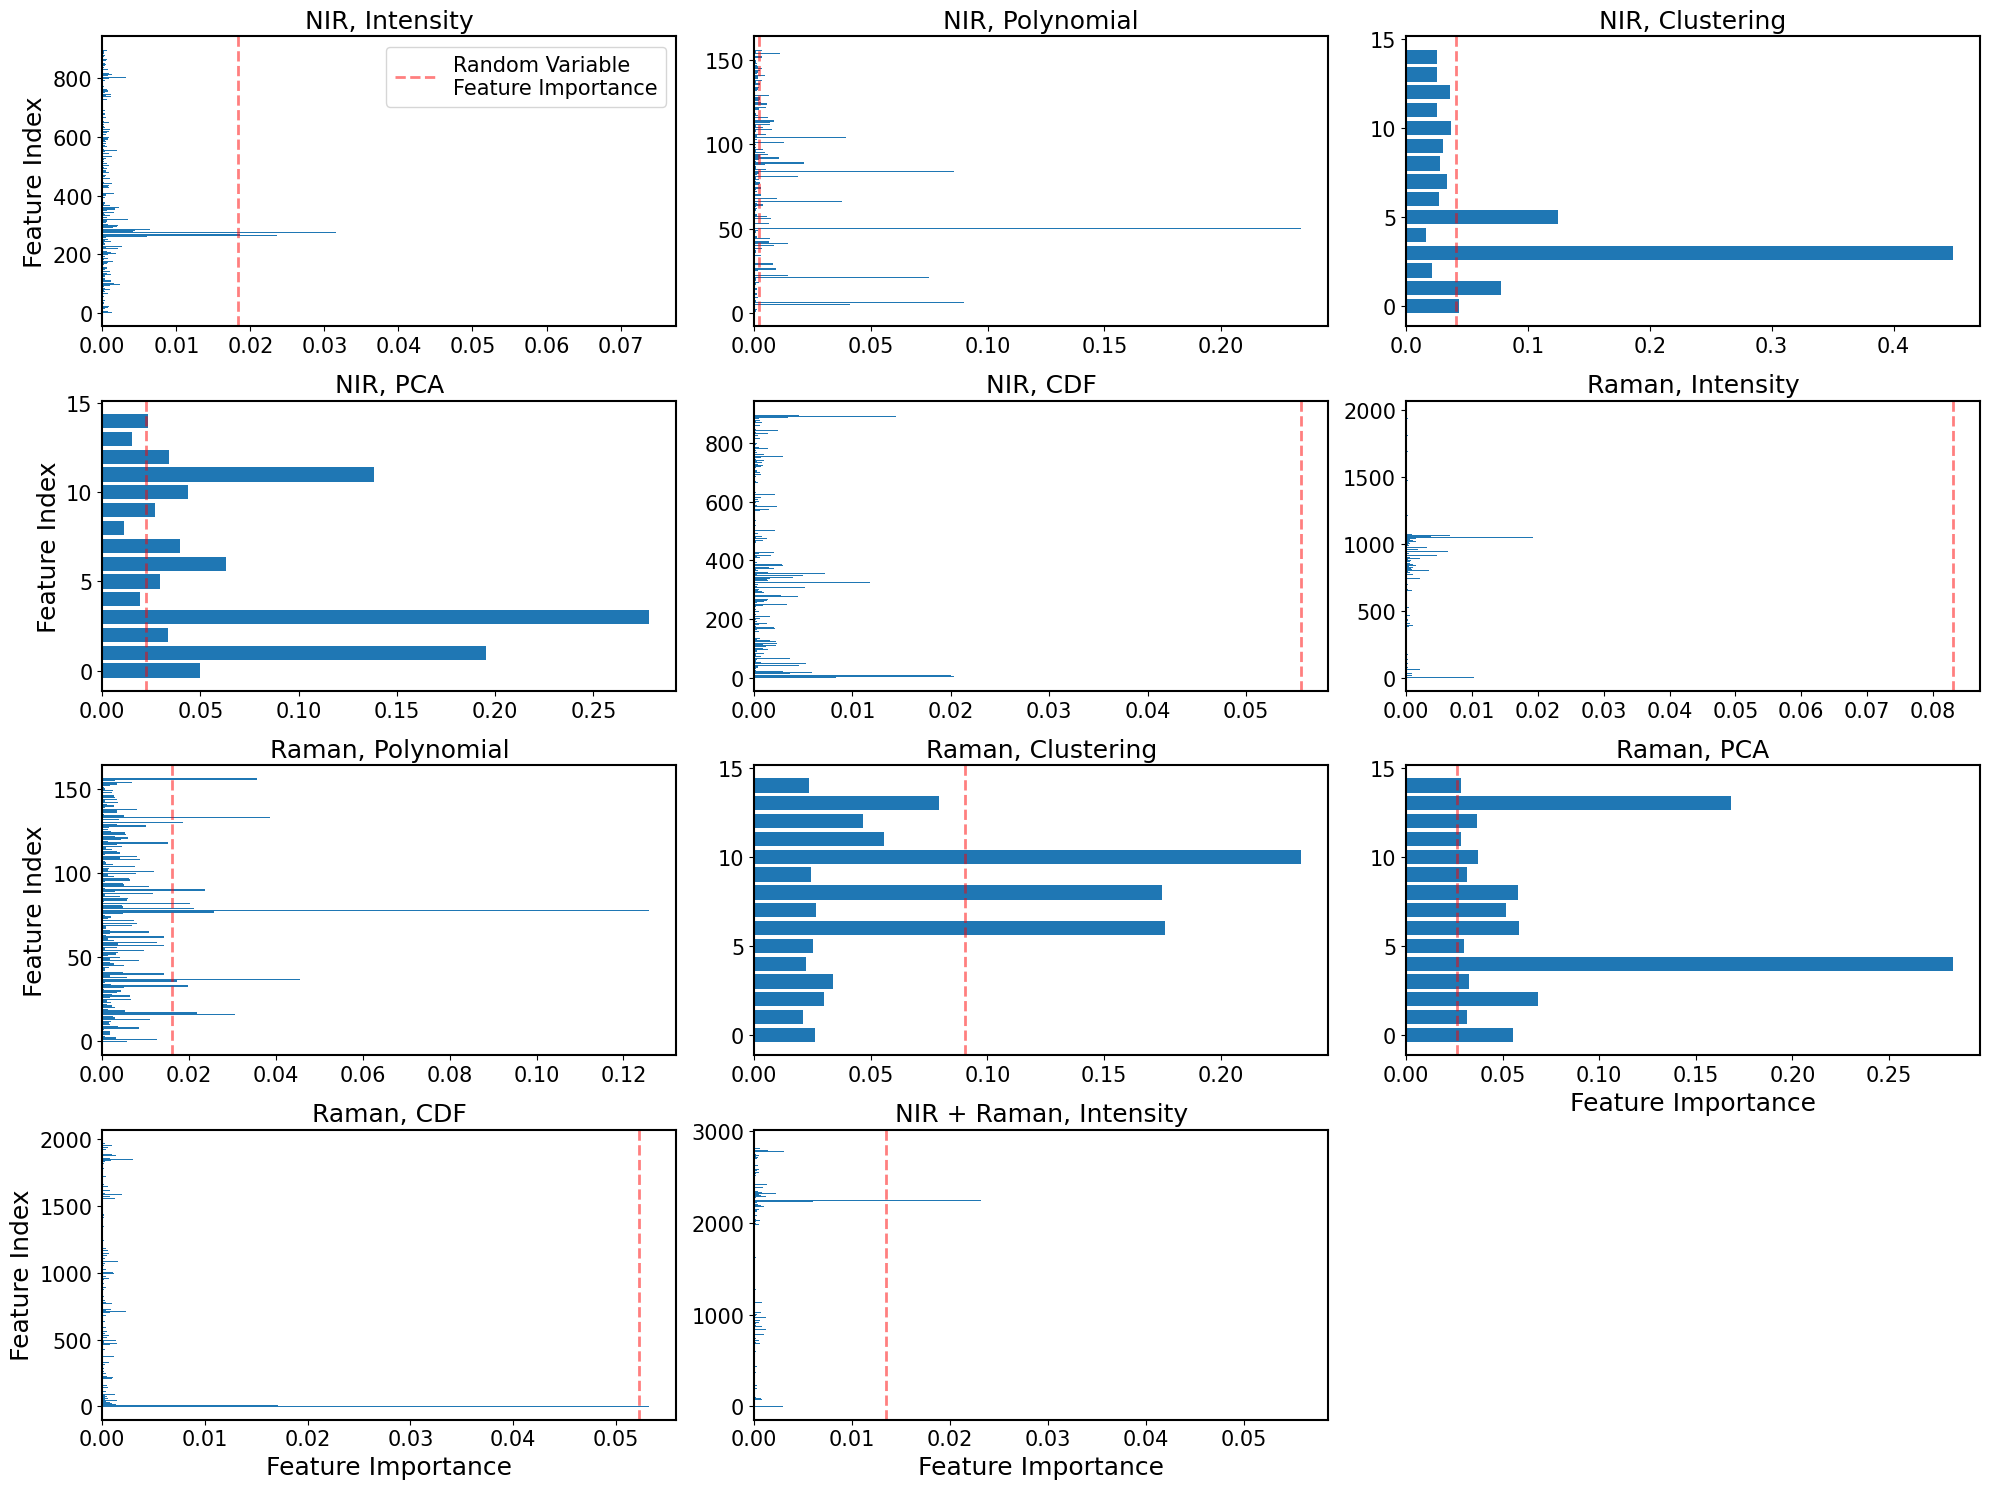

In [18]:
attr_list, importances_list = [], []
for attr_name in ss_f.generated_features:
    try:
        gs = getattr(ss_f, f'{attr_name}_br_RandomForestRegressor')['P'][0]
        importances_list.append(gs.best_estimator_.feature_importances_)
        attr_list.append(attr_name)
    except Exception:
        continue

fig, axs = plt.subplots(4, 3, figsize=(20, 15), sharey=False, constrained_layout=True)
axs = axs.ravel()

for i, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax = axs[i]
    ax.barh(range(len(feature_importances)), feature_importances)
    ymin, ymax = ax.get_ylim()
    ax.vlines(rv_importance[f'{attr_name}_br_RandomForestRegressor'], ymin, ymax,
              color='r', linestyle='--', linewidth=2, alpha=0.5,
              label='Random Variable\nFeature Importance')
    ax.set_ylim(ymin, ymax)
    ax.set_title(PRETTY_LABELS_DICT.get(attr_name, attr_name), fontsize=18)
    ax.tick_params(axis='both', labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

axs[0].legend(fontsize=15)
for j in [0, 3, 6, 9]:
    axs[j].set_ylabel('Feature Index', fontsize=18)
for j in [8, 9, 10]:
    axs[j].set_xlabel('Feature Importance', fontsize=18)
axs[11].axis('off')
plt.tight_layout()
plt.savefig('Figures/SuppFig5.pdf', dpi=300, bbox_inches='tight')

## SI Figure 6: LCEN Feature Importance

Absolute value of LCEN coefficients for each feature/modality pair.
Inset legend shows best-fit hyperparameters and the number of features
selected by the clip step.  Red dashed line: random variable threshold.

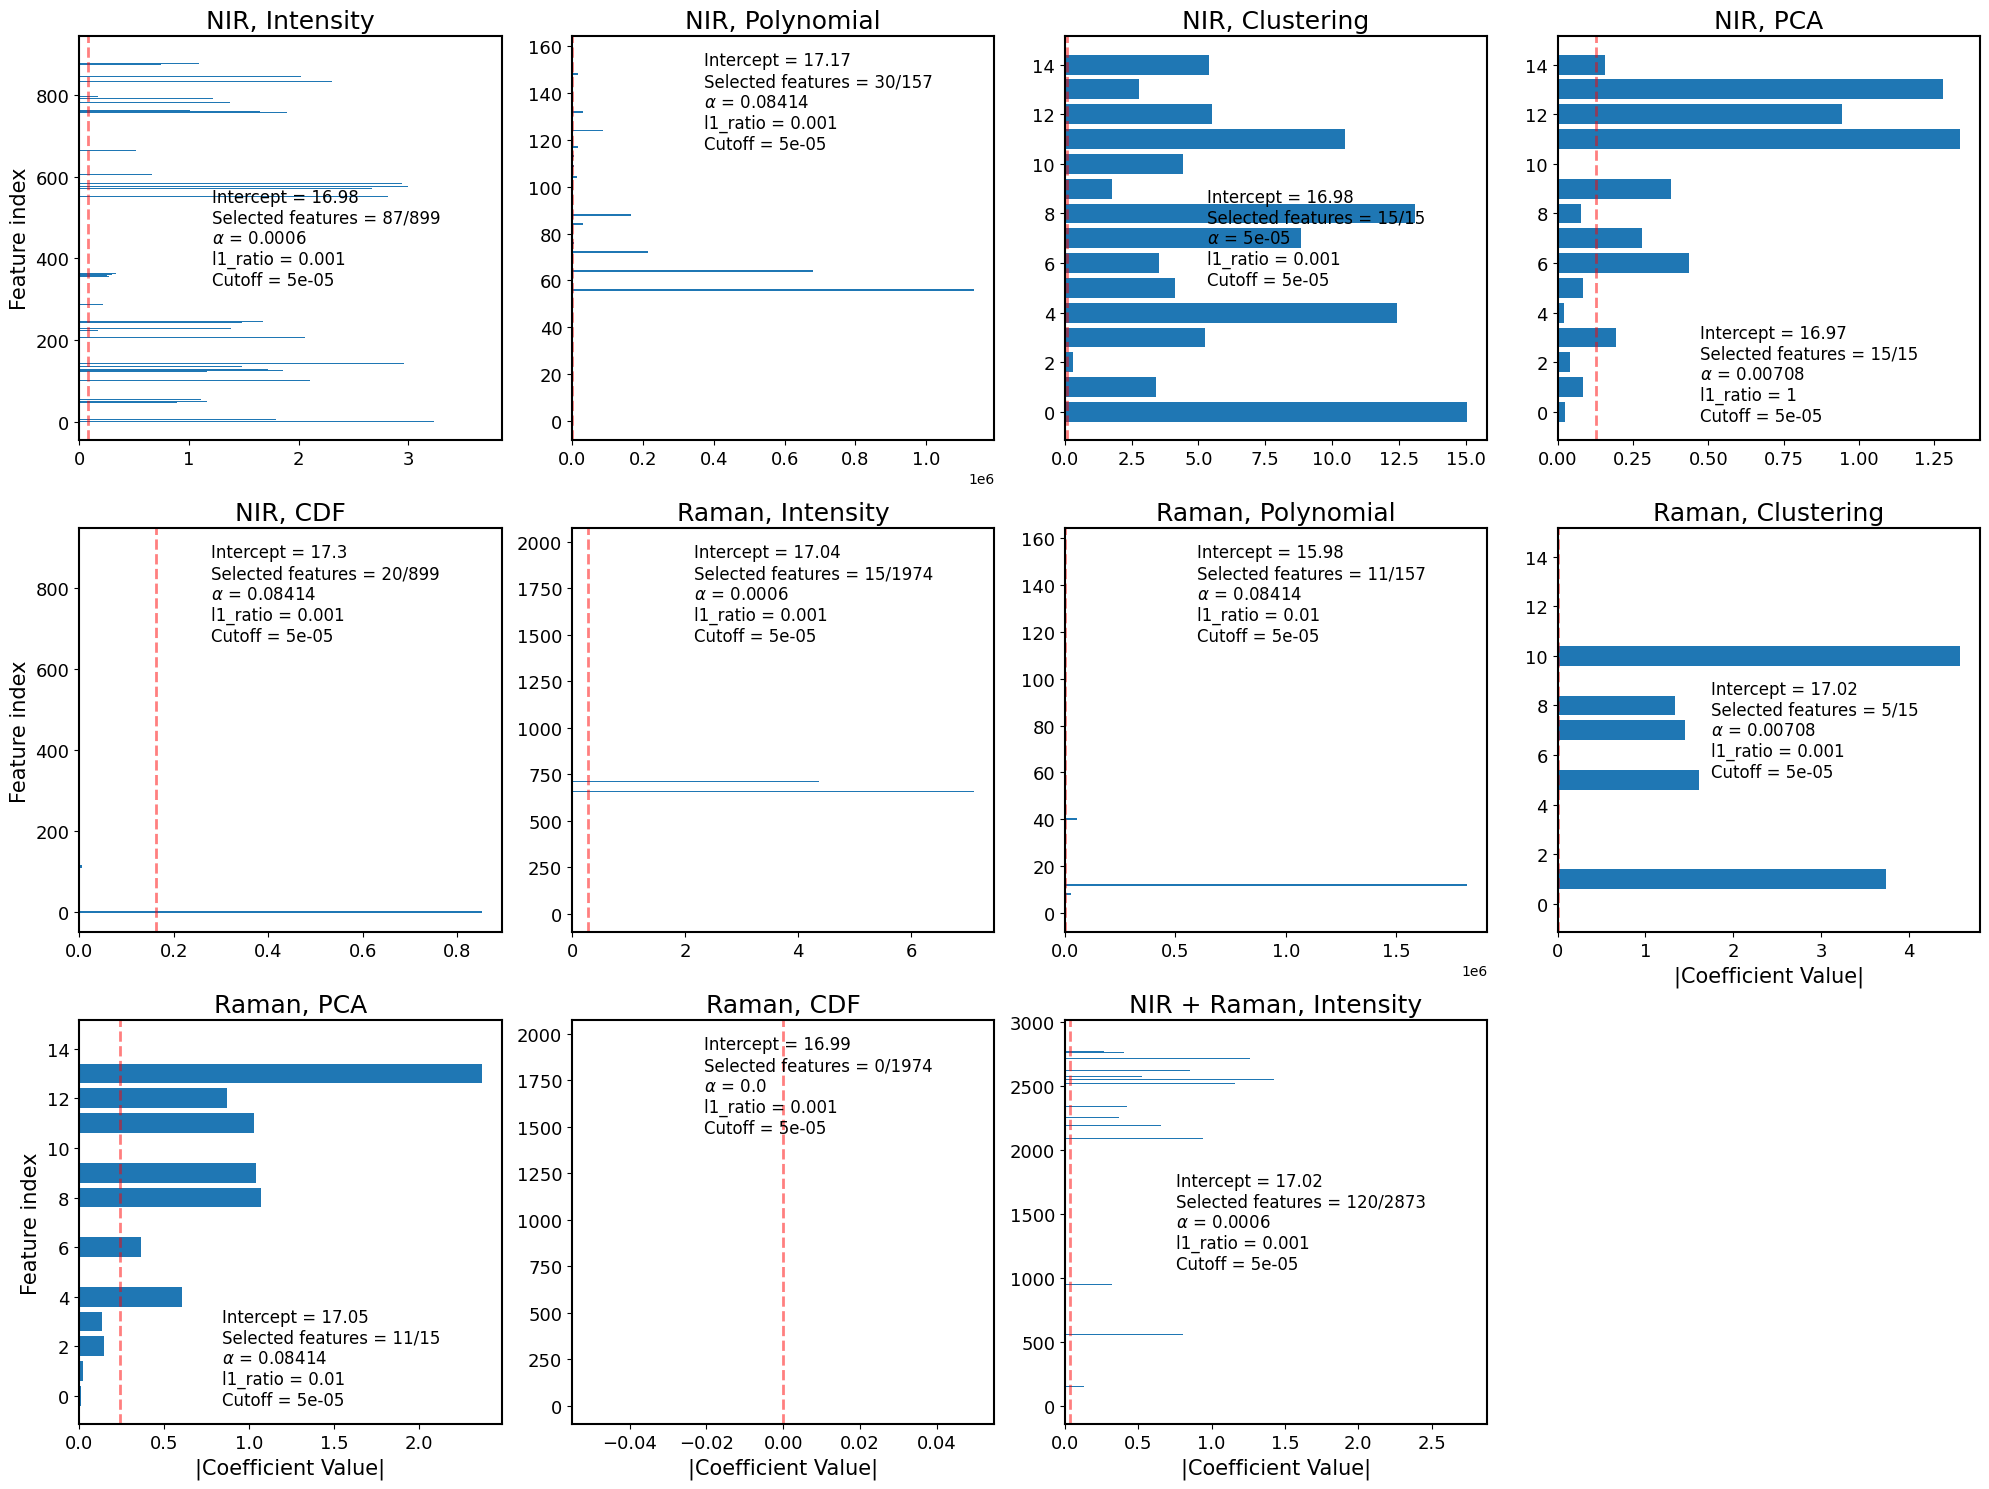

In [19]:
attr_list, importances_list, coef_names = [], [], []
alpha_list, l1_list, cutoff_list = [], [], []

for attr_name in ss_f.generated_features:
    try:
        lcen_fit     = getattr(ss_f, f'{attr_name}_br_LCEN')
        model_params = np.array(lcen_fit['model_params'])
        coefs        = np.abs(np.array([float(c) for c in model_params[:, 1]]))
        attr_list.append(attr_name)
        importances_list.append(coefs)
        coef_names.append(model_params[:, 0])
        alpha_list.append(lcen_fit['model_hyper']['alpha'])
        l1_list.append(lcen_fit['model_hyper']['l1_ratio'])
        cutoff_list.append(lcen_fit['model_hyper']['cutoff'])
    except Exception:
        continue

fig, axs = plt.subplots(3, 4, figsize=(20, 15), sharey=False, constrained_layout=True)
axs = axs.ravel()

for j, (attr_name, feature_importances) in enumerate(zip(attr_list, importances_list)):
    ax        = axs[j]
    par_names = coef_names[j]
    n_features = getattr(ss_f, attr_name).shape[-1]
    lcen_arr  = np.zeros(n_features)
    intercept = 0.0
    for name, val in zip(par_names, feature_importances):
        if name == 'intercept':
            intercept = val
            continue
        lcen_arr[int(name.replace('x', ''))] = val
    lcen_arr = np.abs(lcen_arr)
    rv_val    = rv_importance[f'{attr_name}_br_LCEN']
    idx_above = np.where(lcen_arr > rv_val)[0]
    # ax.barh(idx_above, lcen_arr[idx_above])
    if attr_name=='nir_cdf':
        ax.barh(np.arange(n_features), lcen_arr, height=5)
    else: 
        ax.barh(np.arange(n_features), lcen_arr)
    ymin, ymax = ax.get_ylim()
    if len(idx_above) == 1: 
        ymin -=1 
        ymax +=1 
    ax.vlines(rv_val, ymin, ymax, color='r', linestyle='--', linewidth=2, alpha=0.5,
              label='Random Variable\nCoefficient')
    ax.set_ylim(ymin, ymax)
    ax.set_title(PRETTY_LABELS_DICT.get(attr_name, attr_name), fontsize=18)
    ax.tick_params(axis='both', labelsize=13)
    legend_text = (
        f'Intercept = {np.round(intercept, 2)}\n'
        f'Selected features = {len(lcen_arr.nonzero()[0])}/{n_features}\n'
        f'$\\alpha$ = {np.round(alpha_list[j], 5)}\n'
        f'l1_ratio = {np.round(l1_list[j], 3)}\n'
        f'Cutoff = {cutoff_list[j]:g}'
    )
    ax.legend(
        [Line2D([0], [0], marker='o', color='w', markerfacecolor='k', markersize=0)],
        [legend_text], fontsize=12, frameon=False, markerfirst=False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

for j in [0, 4, 8]:
    axs[j].set_ylabel('Feature index', fontsize=15)
for j in [7, 8, 9, 10]:
    axs[j].set_xlabel('|Coefficient Value|', fontsize=15)
axs[-1].axis('off')
plt.tight_layout()
plt.savefig('Figures/SuppFig6.pdf', dpi=300, bbox_inches='tight')

## Correlation Analysis

Compute Pearson correlation (`r`) and mutual information (`MIF`) between
each feature set and °Brix, then join with % RMSE.  Results are saved as
CSV files and used in Figure 6.

In [20]:
# Pearson r and MIF for the full feature vectors
corr = ss_f.pearson_feature_selection('br', ss_f.generated_features,
                                       return_vals=True, k=len(ss_f.generated_features))
mif  = ss_f.mutual_info_feature_selection('br', ss_f.generated_features,
                                            return_vals=True, k=len(ss_f.generated_features))

corr_df = pd.DataFrame({'r':   [np.abs(corr[k]).max() for k in corr]}, index=list(corr))
mif_df  = pd.DataFrame({'MIF': [np.abs(mif[k]).max()  for k in mif]},  index=list(mif))
merged  = corr_df.merge(mif_df, left_index=True, right_index=True)

temp = (pd.DataFrame(ss_f.best_fits)[['RandomForestRegressor', 'LCEN']]
        / np.max(ss_f.br) * 100)
temp = temp.rename(index=lambda x: x.replace('_br', ''))

merged_err = merged.join(temp, how='inner')
merged_err.columns = ['r', 'MIF', 'RF', 'LCEN']
merged_err = merged_err.rename(PRETTY_LABELS_DICT, axis=0)
merged_err.to_csv('Figures/Grapes_rMAX_all.csv')

# Pearson r on model-selected features
selected_r = {'RF_r': {}, 'LCEN_r': {}}
num_features = 20  # default fallback; overwritten by LCEN selection below
for feat in ss_f.generated_features:
    # --- LCEN: use features that survived the clip step ---
    if hasattr(ss_f, feat + '_br_LCEN'):
        trained = getattr(ss_f, feat + '_br_LCEN')
        vals, sel_feats = LCEN_selected_features(trained, -1)
        if len(sel_feats) > 0:
            selected_X = getattr(ss_f, feat)[:, sel_feats]
            r = r_regression(selected_X, ss_f.br)
            selected_r['LCEN_r'][feat] = r
            num_features = len(r)

    # --- RF: top-N features by importance (N = number selected by LCEN above) ---
    if hasattr(ss_f, feat + '_br_RandomForestRegressor'):
        trained = getattr(ss_f, feat + '_br_RandomForestRegressor')
        fi = trained['P'][0].best_estimator_.feature_importances_
        sel_feats = np.argsort(fi)[::-1][:num_features]
        selected_X = getattr(ss_f, feat)[:, sel_feats]
        r = r_regression(selected_X, ss_f.br)
        selected_r['RF_r'][feat] = r

for agg_fn, fname in [('max', 'Figures/GRAPES_rMAX.csv'),
                       ('mean', 'Figures/GRAPES_rMEAN.csv')]:
    r_df = pd.DataFrame(
        {m: {f: getattr(np, agg_fn)(np.abs(selected_r[m][f])) for f in selected_r[m]}
         for m in selected_r})
    r_rmse = r_df.join(temp, how='inner')
    r_rmse.columns = ['RF_r', 'LCEN_r', 'RF', 'LCEN']
    r_rmse.rename(PRETTY_LABELS_DICT, axis=0).to_csv(fname)

100%|██████████| 12/12 [00:03<00:00,  3.48it/s]


## Figure 6: Linear Correlation Assessment

Side-by-side heatmaps comparing Pearson-r / % RMSE for:
**(a)** XANES + PDF (Ti-oxide bond length) and **(b)** Vis-NIR + Raman (grape °Brix).
Features are sorted by LCEN % RMSE.

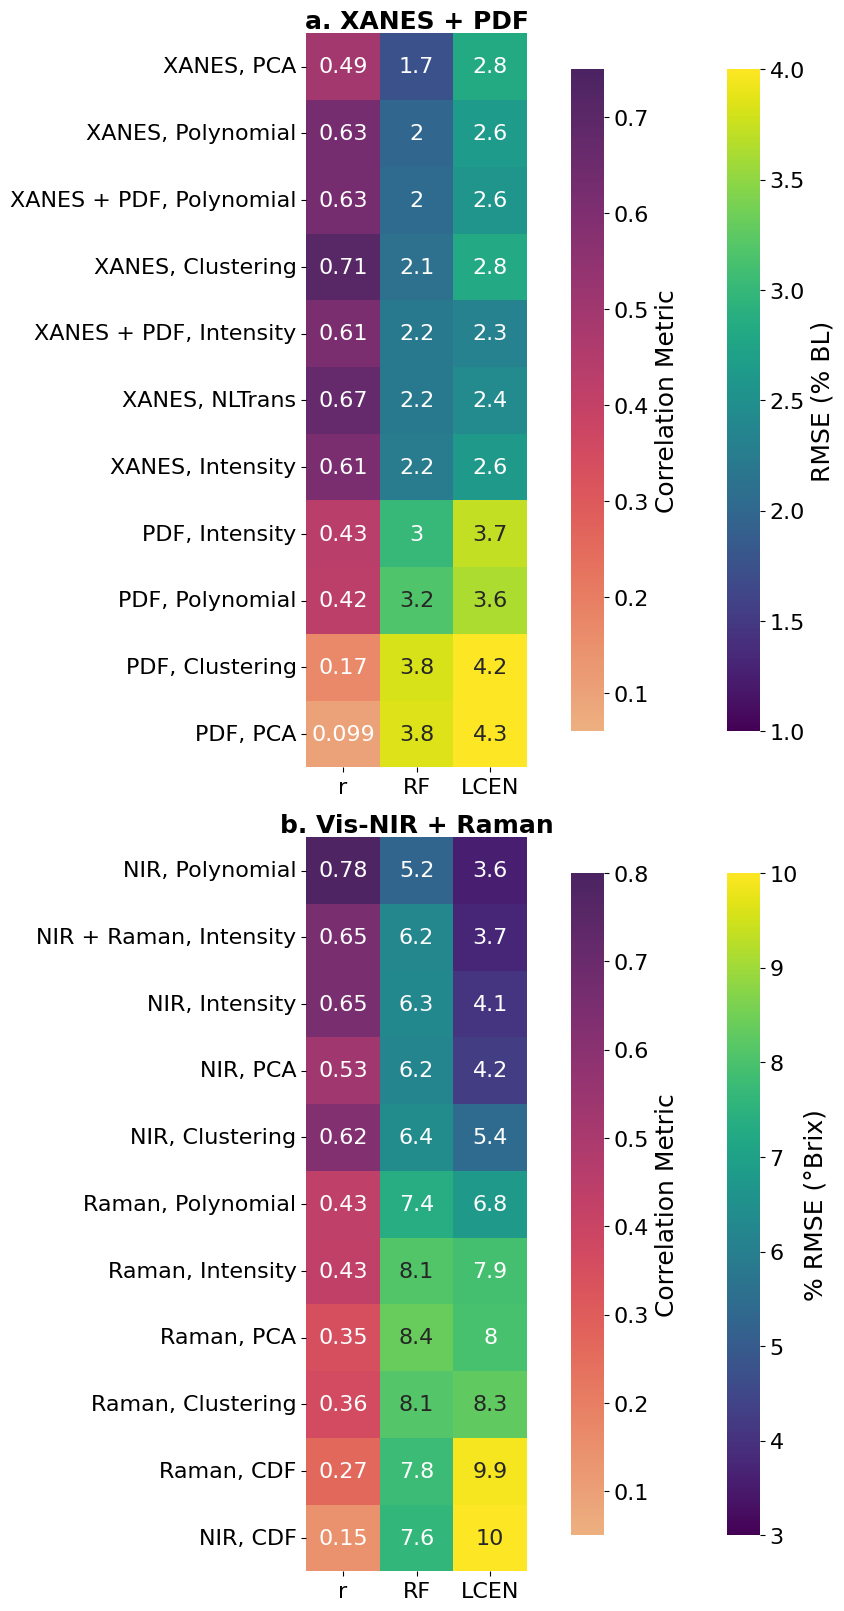

In [21]:
xanes_file  = 'Figures/XANES_rMAX_all.csv'
grapes_file = 'Figures/Grapes_rMAX_all.csv'

fig, (ax2, ax1) = plt.subplots(2, 1, figsize=(9, 16), constrained_layout=True)
labelsize, ticksize, fontsize = 18, 16, 16

df_grapes = pd.read_csv(grapes_file, index_col=0)[['r', 'RF', 'LCEN']]
ax_g, cb1_g, cb2_g = plot_two_heatmaps(
    df_grapes, sort_by='LCEN', vrange1=(3, 10), vrange2=(0.05, 0.8),
    ax=ax1, annot_kws={'fontsize': fontsize})
cb1_g.set_label('% RMSE (°Brix)')
cb2_g.set_label('Correlation Metric')

df_xanes = pd.read_csv(xanes_file, index_col=0)[['r', 'RF', 'LCEN']]
df_xanes = df_xanes.drop(index='XANES, CDF', errors='ignore')
ax_x, cb1_x, cb2_x = plot_two_heatmaps(
    df_xanes, sort_by='RF', vrange1=(1, 4), vrange2=(0.06, 0.75),
    ax=ax2, annot_kws={'fontsize': fontsize})
cb1_x.set_label('RMSE (% BL)')
cb2_x.set_label('Correlation Metric')

for ax in [ax1, ax2, ax_g, ax_x]:
    ax.tick_params(axis='both', labelsize=ticksize)
    ax.xaxis.label.set_size(labelsize)
    ax.yaxis.label.set_size(labelsize)
for cb in [cb1_g, cb2_g, cb1_x, cb2_x]:
    cb.ax.tick_params(labelsize=ticksize)
    cb.set_label(cb.ax.get_ylabel(), fontsize=labelsize)

for ax, title in zip([ax2, ax1], ['a. XANES + PDF', 'b. Vis-NIR + Raman']):
    ax.set_title(title, ha='center', va='center', fontsize=18, fontweight='bold',
                 transform=ax.transAxes, pad=5)

plt.savefig('Figures/Fig6.pdf', dpi=300, bbox_inches='tight')

## Figure 5: Fused LASSO Selected Features

Train Fused LASSO models on raw NIR intensity features across a range of
regularization strengths `α`.  Positive/negative coefficients indicate
spectral regions positively/negatively correlated with °Brix.

`dfs_by_alpha` is a dict of DataFrames giving the coefficient value and
wavelength range for each contiguous flat segment (SI Table 5).

In [ ]:
alpha_arr = [0.1, 0.3, 0.5, 0.7, 0.9, 1.5, 4.0, 10.0]
coefs, scores = {}, {}
for alpha in alpha_arr:
    fl = FusedLasso(alpha=alpha, solver_path=['SCS'])
    try:
        fl.fit(ss_f_unscaled.nir_pointwise_features_train, ss_f_unscaled.br_train)
        ypred        = fl.predict(ss_f_unscaled.nir_pointwise_features_test)
        coefs[alpha]  = fl.coef_
        scores[alpha] = root_mean_squared_error(ss_f_unscaled.br_test, ypred)
    except RuntimeError as e:
        print(f'Fused LASSO failed at alpha={alpha}: {e}')

min_alpha = min(scores, key=scores.get)
print(f'Best alpha = {min_alpha}, % RMSE = {round(scores[min_alpha] / np.max(br) * 100, 2)}')

# Contiguous flat-segment tables (SI Table 5)
dfs_by_alpha = {}
for alpha, coeff_arr in coefs.items():
    coeff_rounded = np.round(coeff_arr, 3)
    breaks = np.concatenate(
        ([0], np.where(np.diff(coeff_rounded) != 0)[0] + 1, [len(coeff_rounded)]))
    rows = [{'coef': coeff_rounded[s],
             'x_range_start': ss_f.nir_xaxis[s],
             'x_range_end':   ss_f.nir_xaxis[e - 1]}
            for s, e in zip(breaks[:-1], breaks[1:])]
    dfs_by_alpha[alpha] = pd.DataFrame(rows)

print_dfs = True 
if print_dfs:
    for alpha, df_alpha in dfs_by_alpha.items():
        print(f'\nalpha = {alpha}')
        print(df_alpha.to_latex(index=False))

(CVXPY) Apr 03 10:40:57 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:40:58 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:44 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:47 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:51 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:55 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:55 AM: Solver SCS succeeds
(CVXPY) Apr 03 10:41:55 AM: Solver SCS succeeds


Best alpha = 0.1, % RMSE = 4.59


In [30]:
for alpha, df_alpha in dfs_by_alpha.items():
    print(f'\nalpha = {alpha}')
    print(df_alpha.to_latex(index=False))


alpha = 0.1
\begin{tabular}{rrr}
\toprule
coef & x_range_start & x_range_end \\
\midrule
0.012000 & 401 & 443 \\
-0.025000 & 444 & 489 \\
0.014000 & 490 & 519 \\
0.015000 & 520 & 539 \\
0.017000 & 540 & 606 \\
0.013000 & 607 & 622 \\
0.012000 & 623 & 652 \\
0.011000 & 653 & 666 \\
0.010000 & 667 & 680 \\
0.009000 & 681 & 689 \\
-0.018000 & 690 & 734 \\
-0.017000 & 735 & 773 \\
-0.016000 & 774 & 812 \\
0.030000 & 813 & 879 \\
0.029000 & 880 & 965 \\
-0.154000 & 966 & 991 \\
-0.091000 & 992 & 1107 \\
0.191000 & 1108 & 1165 \\
-0.005000 & 1166 & 1166 \\
-0.119000 & 1167 & 1229 \\
0.094000 & 1230 & 1299 \\
\bottomrule
\end{tabular}


alpha = 0.3
\begin{tabular}{rrr}
\toprule
coef & x_range_start & x_range_end \\
\midrule
-0.006000 & 401 & 489 \\
0.011000 & 490 & 510 \\
0.012000 & 511 & 546 \\
0.013000 & 547 & 612 \\
0.012000 & 613 & 631 \\
0.011000 & 632 & 646 \\
0.010000 & 647 & 659 \\
0.009000 & 660 & 676 \\
0.008000 & 677 & 694 \\
-0.011000 & 695 & 759 \\
-0.012000 & 760 & 806 \\
-0.01

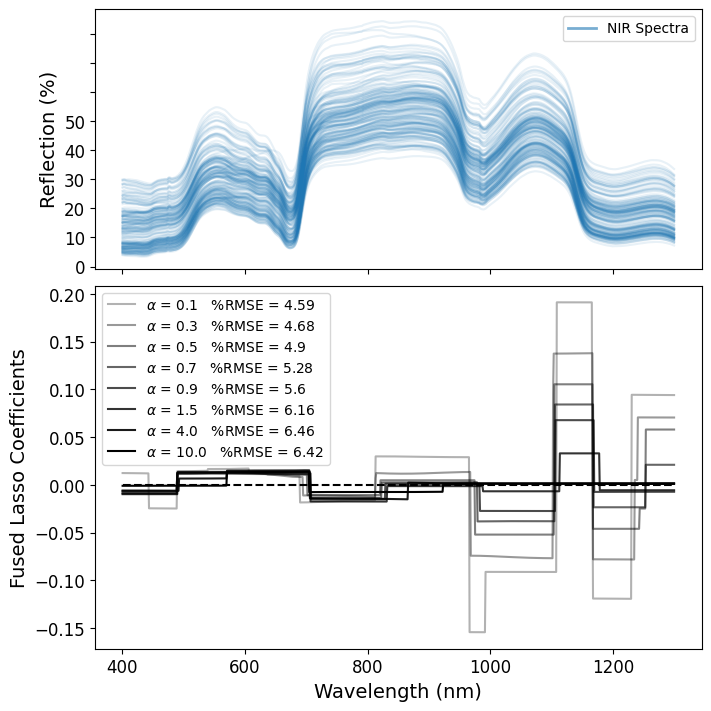

In [23]:
fontsize = 14
f, (ax1, ax2) = plt.subplots(2, 1,
                              gridspec_kw={'height_ratios': [0.5, 0.7]},
                              figsize=(7, 7), sharex=True, constrained_layout=True)

for spec in XSF_br:
    ax1.plot(ss_f.nir_xaxis, spec[selected_wls], alpha=0.1, color='tab:blue')

alpha_opacity = np.linspace(0.3, 1, len(coefs))
for i, alpha in enumerate(coefs):
    ax2.plot(ss_f.nir_xaxis, coefs[alpha], color='k', alpha=alpha_opacity[i],
             label=rf'$\alpha$ = {alpha}   %RMSE = {round(scores[alpha] / np.max(ss_f.br) * 100, 2)}')
ax2.plot(ss_f.nir_xaxis, np.zeros(len(ss_f.nir_xaxis)), 'k--')

ax1.set_ylabel('Reflection (%)', fontsize=fontsize)
ax2.set_xlabel('Wavelength (nm)', fontsize=fontsize)
ax2.set_ylabel('Fused Lasso Coefficients', fontsize=fontsize)

ax1.legend(
    handles=[Line2D([0], [0], color='tab:blue', lw=2, alpha=0.6, label='NIR Spectra')],
    loc='upper right', frameon=True)
ax2.legend()

for ax in [ax1, ax2]:
    ax.set_yticklabels(ax.get_yticklabels(), size=12)
ax2.set_xticklabels(ax2.get_xticklabels(), size=12)

plt.savefig('Figures/Fig5.pdf', dpi=300, bbox_inches='tight')

## LCEN Hyperparameter Sensitivity Analysis

Evaluate % RMSE when the clip cutoff, regularization strength `α`,
and ElasticNet L1 ratio are varied independently, with the other two
fixed at their CV-optimal values (`α = 0.00708`, cutoff = 5×10⁻⁵, L1 ratio = 0.01).

In [24]:
bestalpha   = 0.00707945784384138
cutoff_used = 5e-5
fixed_l1    = 0.01

cutoff_arr = [1, 5e-1, 3e-1, 1e-1, 7e-2, 5e-2, 3e-2, 1e-2, 5e-3, 5e-4, 5e-5]
alpharange = np.round(np.concatenate(([0], np.logspace(-4.3, 0, 5))), 7)
l1_arr     = [0.001, 0.01, 0.1, 0.3, 0.5, 0.75, 1]

results_cutoff = run_lcen_sensitivity(
    ss_f, 'nir_polynomial_featuresall', 'br', 0.25,
    cutoff_arr, 'cutoff', bestalpha, cutoff_used, fixed_l1)

results_alpha = run_lcen_sensitivity(
    ss_f, 'nir_polynomial_featuresall', 'br', 0.25,
    alpharange, 'alpha', bestalpha, cutoff_used, fixed_l1)

results_l1 = run_lcen_sensitivity(
    ss_f, 'nir_polynomial_featuresall', 'br', 0.25,
    l1_arr, 'l1_ratio', bestalpha, cutoff_used, fixed_l1)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.4415 | Mean relative error = 0.1093
Test set : RMSE = 2.4574 | Mean relative error = 0.1102
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.4415 | Mean relative error = 0.1093
Test set : RMSE = 2.4574 | Mean relative error = 0.1102
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

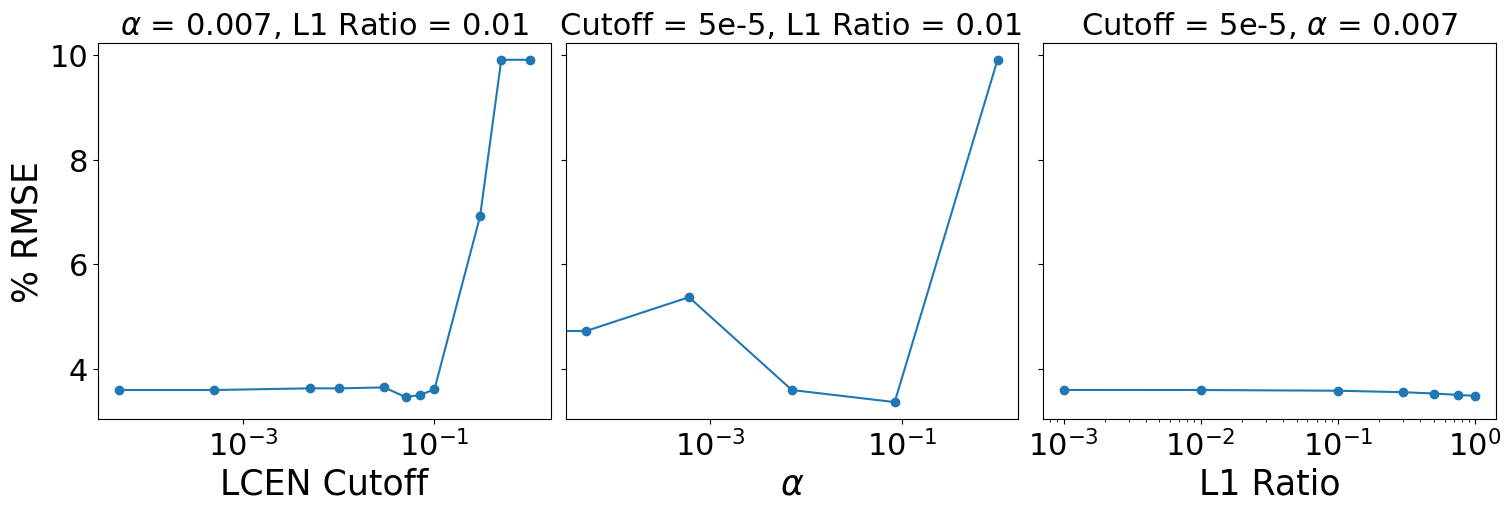

In [25]:
f, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5),
                                    constrained_layout=True, sharey=True)

ax1.plot(cutoff_arr, results_cutoff, marker='o')
ax1.set_xlabel('LCEN Cutoff')
ax1.set_ylabel('% RMSE')
ax1.set_xscale('log')
ax1.set_title(r'$\alpha$ = 0.007, L1 Ratio = 0.01', fontsize=22)

ax2.plot(alpharange, results_alpha, marker='o')
ax2.set_xlabel(r'$\alpha$')
ax2.set_xscale('log')
ax2.set_title(r'Cutoff = 5e-5, L1 Ratio = 0.01', fontsize=22)

ax3.plot(l1_arr, results_l1, marker='o')
ax3.set_xlabel(r'L1 Ratio')
ax3.set_xscale('log')
ax3.set_title(r'Cutoff = 5e-5, $\alpha$ = 0.007', fontsize=22)

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=22)
    ax.xaxis.label.set_size(25)
    ax.yaxis.label.set_size(25)